In [5]:
# سلول ۱: وارد کردن کتابخانه‌ها و تنظیمات اولیه مسیرها
import os
import urllib.request
import zipfile
import numpy as np
from scipy.io import wavfile

# تعریف مسیرهای پایه به صورت ثابت (Constant)
DATA_DIR = './data'
ZIP_PATH = os.path.join(DATA_DIR, 'mini_speech_commands.zip')
EXTRACTED_DIR = os.path.join(DATA_DIR, 'mini_speech_commands')

# ساخت پوشه اصلی در صورت عدم وجود
if not os.path.exists(DATA_DIR):
    os.makedirs(DATA_DIR)
    print(f"📁 پوشه پایه ساخته شد: {DATA_DIR}")
else:
    print(f"✅ پوشه پایه آماده است: {DATA_DIR}")

✅ پوشه پایه آماده است: ./data


In [6]:
# سلول ۲: دانلود ایمن و استخراج داده‌ها (با مدیریت خطای فایل خراب)

def is_zip_valid(filepath):
    """بررسی سلامت و یکپارچگی فایل زیپ"""
    try:
        with zipfile.ZipFile(filepath, 'r') as zip_ref:
            return zip_ref.testzip() is None
    except:
        return False

# بررسی اینکه آیا داده‌ها قبلا استخراج شده‌اند یا خیر
if os.path.exists(EXTRACTED_DIR) and len(os.listdir(EXTRACTED_DIR)) > 0:
    print("✅ داده‌ها قبلاً با موفقیت استخراج شده‌اند. نیازی به عملیات مجدد نیست.")
else:
    url = 'http://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip'
    
    # بررسی و حذف فایل زیپ خراب (اگر وجود داشته باشد)
    if os.path.exists(ZIP_PATH):
        print("🔍 در حال بررسی سلامت فایل زیپ موجود در سیستم...")
        if not is_zip_valid(ZIP_PATH):
            print("⚠️ فایل زیپ خراب است! سیستم در حال حذف و دانلود مجدد است...")
            os.remove(ZIP_PATH)
        else:
            print("✅ فایل زیپ سالم است.")

    # دانلود فایل در صورت عدم وجود
    if not os.path.exists(ZIP_PATH):
        print("⏳ در حال دانلود فایل‌های صوتی (حدود ۱۶۰ مگابایت)...")
        urllib.request.urlretrieve(url, ZIP_PATH)
        print("✅ دانلود با موفقیت انجام شد!")

    # استخراج فایل با بلوک مدیریت خطا
    print("⏳ در حال استخراج فایل‌ها...")
    try:
        with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
            zip_ref.extractall(DATA_DIR)
        print("🎉 استخراج با موفقیت تمام شد! پوشه داده‌ها ایجاد گردید.")
    except zipfile.BadZipFile:
        print("❌ خطا بحرانی: فایل زیپ حتی پس از دانلود مجدد خراب است.")

🔍 در حال بررسی سلامت فایل زیپ موجود در سیستم...
⚠️ فایل زیپ خراب است! سیستم در حال حذف و دانلود مجدد است...
⏳ در حال دانلود فایل‌های صوتی (حدود ۱۶۰ مگابایت)...
✅ دانلود با موفقیت انجام شد!
⏳ در حال استخراج فایل‌ها...
🎉 استخراج با موفقیت تمام شد! پوشه داده‌ها ایجاد گردید.


In [8]:
# سلول ۳: ممیزی داده‌های صوتی (بررسی کیفیت، طول و فایل‌های خراب)

if not os.path.exists(EXTRACTED_DIR):
    print("❌ خطا: پوشه داده‌ها یافت نشد! لطفاً مطمئن شوید سلول ۲ با موفقیت تمام شده است.")
else:
    # استخراج کلمات (فقط پوشه‌ها را در نظر می‌گیریم تا فایل‌های سیستمی مزاحم نشوند)
    words = [d for d in os.listdir(EXTRACTED_DIR) if os.path.isdir(os.path.join(EXTRACTED_DIR, d))]
    print(f"کلمات موجود در مجموعه داده: {words}\n")
    
    if len(words) == 0:
        print("❌ خطا: هیچ پوشه کلمه‌ای در داده‌ها یافت نشد!")
    else:
        first_word = words[0]
        word_dir = os.path.join(EXTRACTED_DIR, first_word)
        print(f"🔍 در حال ممیزی پوشه کلمه نمونه: '{first_word}' ...")

        total_files = 0
        corrupt_files = 0
        durations = []
        sample_rates = set()

        for filename in os.listdir(word_dir):
            if filename.endswith('.wav'):
                total_files += 1
                filepath = os.path.join(word_dir, filename)
                try:
                    # خواندن فایل صوتی
                    sr, data = wavfile.read(filepath)
                    sample_rates.add(sr)
                    
                    # جلوگیری از خطای تقسیم بر صفر
                    if sr > 0:
                        duration = len(data) / sr
                        durations.append(duration)
                except Exception:
                    corrupt_files += 1

        # چاپ گزارش نهایی
        print(f"\n✅ گزارش نهایی ممیزی کلمه '{first_word}':")
        print(f"▫️ تعداد کل فایل‌های بررسی شده: {total_files}")
        if total_files > 0:
            print(f"▫️ نرخ نمونه‌برداری (Sampling Rate): {list(sample_rates)} هرتز")
            print(f"▫️ میانگین طول فایل‌ها: {np.mean(durations):.2f} ثانیه")
            print(f"▫️ کوتاه‌ترین فایل: {np.min(durations):.2f} ثانیه")
            print(f"▫️ طولانی‌ترین فایل: {np.max(durations):.2f} ثانیه")
        print(f"▫️ فایل‌های خراب یا ناخوانا: {corrupt_files}")

کلمات موجود در مجموعه داده: ['down', 'go', 'left', 'no', 'right', 'stop', 'up', 'yes']

🔍 در حال ممیزی پوشه کلمه نمونه: 'down' ...

✅ گزارش نهایی ممیزی کلمه 'down':
▫️ تعداد کل فایل‌های بررسی شده: 1000
▫️ نرخ نمونه‌برداری (Sampling Rate): [16000] هرتز
▫️ میانگین طول فایل‌ها: 0.99 ثانیه
▫️ کوتاه‌ترین فایل: 0.47 ثانیه
▫️ طولانی‌ترین فایل: 1.00 ثانیه
▫️ فایل‌های خراب یا ناخوانا: 0


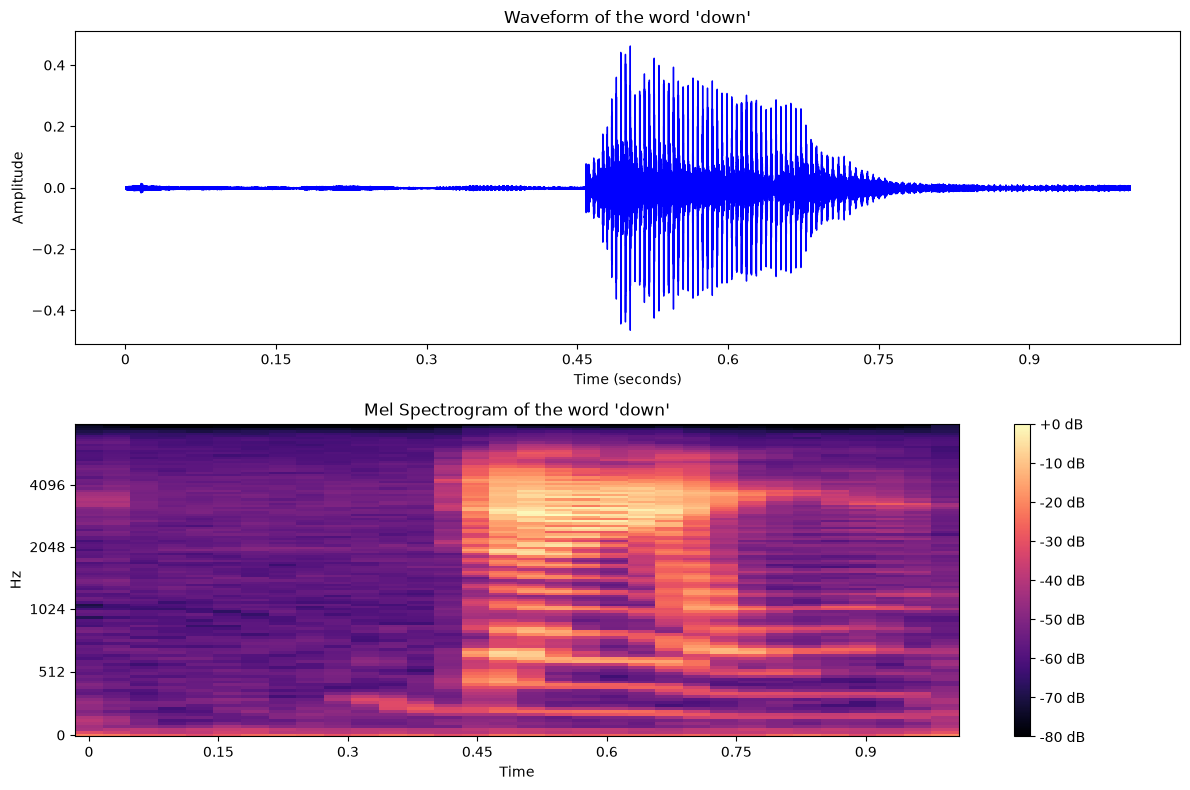

In [11]:
# سلول ۴: رسم نمودار شکل موج (Waveform) و طیف‌نگار (Spectrogram)
import matplotlib.pyplot as plt
import librosa
import librosa.display
import os
import numpy as np

# انتخاب اولین فایل صوتی از همان کلمه‌ای که ممیزی کردیم
sample_audio_path = os.path.join(word_dir, os.listdir(word_dir)[0])

# بارگذاری فایل صوتی با کتابخانه تخصصی librosa
y, sr = librosa.load(sample_audio_path, sr=None)

# تنظیم ابعاد تصویر
plt.figure(figsize=(12, 8))

# ۱. رسم شکل موج (Waveform): تغییرات دامنه صدا در طول زمان
plt.subplot(2, 1, 1)
librosa.display.waveshow(y, sr=sr, color='blue')
plt.title(f"Waveform of the word '{first_word}'")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

# ۲. رسم طیف‌نگار (Mel Spectrogram): فرکانس‌های موجود در صدا
plt.subplot(2, 1, 2)
# استخراج ویژگی‌های فرکانسی (اسپکتروگرام)
mel_spect = librosa.feature.melspectrogram(y=y, sr=sr)
# تبدیل به مقیاس دسی‌بل برای نمایش بهتر
mel_spect_db = librosa.power_to_db(mel_spect, ref=np.max)

librosa.display.specshow(mel_spect_db, sr=sr, x_axis='time', y_axis='mel')
plt.colorbar(format='%+2.0f dB')
plt.title(f"Mel Spectrogram of the word '{first_word}'")

# نمایش مرتب نمودارها
plt.tight_layout()
plt.show()

In [13]:
# سلول ۵: ممیزی جامع تمام کلاس‌ها و استخراج شناسه گویندگان (Speaker Audit)
import pandas as pd

print("⏳ در حال ممیزی جامع تمام پوشه‌ها و استخراج اطلاعات گویندگان...")

audio_metadata = []
corrupt_files = 0

# بررسی تمام کلمات پیدا شده در پوشه استخراج
for word in words:
    word_path = os.path.join(EXTRACTED_DIR, word)
    
    for filename in os.listdir(word_path):
        if filename.endswith('.wav'):
            filepath = os.path.join(word_path, filename)
            
            # استخراج شناسه گوینده: نام فایل‌ها در مجموعه گوگل ساختار شناسه_نویز_شماره دارند
            # مثال: 00b01445_nohash_0.wav -> شناسه گوینده: 00b01445
            speaker_id = filename.split('_')[0]
            
            try:
                sr, data = wavfile.read(filepath)
                duration = len(data) / sr if sr > 0 else 0
                
                audio_metadata.append({
                    'Word_Class': word,
                    'Speaker_ID': speaker_id,
                    'Duration_sec': duration,
                    'Sample_Rate': sr,
                    'Filename': filename
                })
            except Exception:
                corrupt_files += 1

# تبدیل لیست به دیتافریم پانداز برای تحلیل راحت‌تر
df_audio = pd.DataFrame(audio_metadata)

print(f"✅ ممیزی به پایان رسید. پایگاه داده تحلیلی با {len(df_audio)} فایل صوتی ایجاد شد.")
print(f"▫️ تعداد کل فایل‌های خراب/ناخوانا در کل داده‌ها: {corrupt_files}")

print("\n📊 توزیع فایل‌ها در هر کلاس (تعداد نمونه‌های هر کلمه):")
display(df_audio['Word_Class'].value_counts().to_frame(name='تعداد'))

print(f"\n👥 ممیزی گویندگان: تعداد کل گویندگان یکتا (Unique Speakers) = {df_audio['Speaker_ID'].nunique()} نفر")

print("\n⏱️ بررسی آماری طول فایل‌ها (ثانیه):")
display(df_audio['Duration_sec'].describe().to_frame(name='آمارهای طول صدا'))

print("\n🔍 ۵ سطر اول پایگاه داده ما:")
display(df_audio.head())

⏳ در حال ممیزی جامع تمام پوشه‌ها و استخراج اطلاعات گویندگان...
✅ ممیزی به پایان رسید. پایگاه داده تحلیلی با 8000 فایل صوتی ایجاد شد.
▫️ تعداد کل فایل‌های خراب/ناخوانا در کل داده‌ها: 0

📊 توزیع فایل‌ها در هر کلاس (تعداد نمونه‌های هر کلمه):


,تعداد
Word_Class,
down,1000
go,1000
left,1000
no,1000
right,1000
stop,1000
up,1000
yes,1000



👥 ممیزی گویندگان: تعداد کل گویندگان یکتا (Unique Speakers) = 1750 نفر

⏱️ بررسی آماری طول فایل‌ها (ثانیه):


,آمارهای طول صدا
count,8000.000000
mean,0.983703
std,0.061426
min,0.426687
25%,1.000000
50%,1.000000
75%,1.000000
max,1.000000



🔍 ۵ سطر اول پایگاه داده ما:


,Word_Class,Speaker_ID,Duration_sec,Sample_Rate,Filename
0,down,004ae714,1.0,16000,004ae714_nohash_0.wav
1,down,00b01445,1.0,16000,00b01445_nohash_1.wav
2,down,00f0204f,1.0,16000,00f0204f_nohash_0.wav
3,down,0132a06d,1.0,16000,0132a06d_nohash_1.wav
4,down,0132a06d,1.0,16000,0132a06d_nohash_4.wav


In [14]:
# سلول ۶: تحلیل عمیق گویندگان و شناسایی کلیپ‌های کم‌انرژی (سکوت/نویز)
import numpy as np

print("📊 ۱. بررسی توزیع نمونه‌های گویندگان در کلاس‌های مختلف:")
speaker_counts = df_audio['Speaker_ID'].value_counts()
print(f"▫️ پُرکارترین گوینده، {speaker_counts.max()} نمونه صدا در این مجموعه دارد.")

# ایجاد ماتریس گوینده-کلاس (Crosstab) برای ۵ گوینده پرکار
top_speakers = speaker_counts.head(5).index
speaker_class_matrix = pd.crosstab(df_audio['Speaker_ID'], df_audio['Word_Class'])

display(speaker_class_matrix.loc[top_speakers])
print("💡 نتیجه ممیزی گوینده: همان‌طور که در ماتریس بالا می‌بینید، یک گوینده کلمات مختلفی را ادا کرده است. این اثبات می‌کند که برای جلوگیری از نشت اطلاعات، باید تقسیم‌بندی داده‌ها را حتماً بر اساس Speaker_ID انجام دهیم نه به صورت تصادفی.")

print("\n🔍 ۲. ممیزی انرژی، سکوت و نویز پس‌زمینه:")
print("⏳ در حال محاسبه دامنه (Amplitude) برای یافتن فایل‌های کم‌انرژی...")

# محاسبه ماکزیمم دامنه مطلق برای تمام فایل‌ها
amplitudes = []
for idx, row in df_audio.iterrows():
    filepath = os.path.join(EXTRACTED_DIR, row['Word_Class'], row['Filename'])
    try:
        sr, data = wavfile.read(filepath)
        # اگر داده خالی نباشد، بیشترین سطح صدا محاسبه می‌شود
        amplitudes.append(np.max(np.abs(data)) if len(data) > 0 else 0)
    except:
        amplitudes.append(0)

df_audio['Max_Amplitude'] = amplitudes

print("▫️ آمار کلی انرژی (بیشترین دامنه) فایل‌ها:")
display(df_audio['Max_Amplitude'].describe().to_frame(name='Max Amplitude'))

# شناسایی فایل‌های بسیار ضعیف (۱ درصد پایین داده‌ها از نظر بلندی صدا)
low_energy_threshold = df_audio['Max_Amplitude'].quantile(0.01)
low_energy_files = df_audio[df_audio['Max_Amplitude'] <= low_energy_threshold]

print(f"\n⚠️ تعداد {len(low_energy_files)} فایل با انرژی بسیار پایین (دامنه <= {low_energy_threshold:.0f}) شناسایی شد.")
print("این فایل‌ها احتمالاً حاوی سکوت خالص، قطعی میکروفون، یا نویز بسیار ضعیف هستند.")
display(low_energy_files.head())

📊 ۱. بررسی توزیع نمونه‌های گویندگان در کلاس‌های مختلف:
▫️ پُرکارترین گوینده، 33 نمونه صدا در این مجموعه دارد.


Word_Class,down,go,left,no,right,stop,up,yes
Speaker_ID,,,,,,,,
c120e80e,6,5,5,1,5,1,4,6
3c257192,3,4,4,4,3,3,3,3
c1d39ce8,1,3,4,2,2,7,5,3
8012c69d,3,3,4,2,2,4,2,4
cb8f8307,2,5,6,2,1,2,1,5


💡 نتیجه ممیزی گوینده: همان‌طور که در ماتریس بالا می‌بینید، یک گوینده کلمات مختلفی را ادا کرده است. این اثبات می‌کند که برای جلوگیری از نشت اطلاعات، باید تقسیم‌بندی داده‌ها را حتماً بر اساس Speaker_ID انجام دهیم نه به صورت تصادفی.

🔍 ۲. ممیزی انرژی، سکوت و نویز پس‌زمینه:
⏳ در حال محاسبه دامنه (Amplitude) برای یافتن فایل‌های کم‌انرژی...
▫️ آمار کلی انرژی (بیشترین دامنه) فایل‌ها:


,Max Amplitude
count,8000.000000
mean,15173.059500
std,9913.848138
min,5.000000
25%,6612.750000
50%,13200.000000
75%,24110.250000
max,32767.000000



⚠️ تعداد 80 فایل با انرژی بسیار پایین (دامنه <= 171) شناسایی شد.
این فایل‌ها احتمالاً حاوی سکوت خالص، قطعی میکروفون، یا نویز بسیار ضعیف هستند.


,Word_Class,Speaker_ID,Duration_sec,Sample_Rate,Filename,Max_Amplitude
243,down,3f2b358d,1.0,16000,3f2b358d_nohash_1.wav,101
277,down,4a1e736b,1.0,16000,4a1e736b_nohash_4.wav,8
731,down,c0445658,1.0,16000,c0445658_nohash_4.wav,5
807,down,ced835d3,1.0,16000,ced835d3_nohash_2.wav,55
808,down,ced835d3,1.0,16000,ced835d3_nohash_3.wav,42
